In [1]:
import pandas as pd
from pathlib import Path

root = Path.cwd() if (Path.cwd() / "data" / "train.csv").exists() else Path.cwd().parent
df = pd.read_csv(
    root / "data" / "train.csv",
    sep=";",
    quotechar="'",
    header=None,
    names=["label", "text"],
)

df["word_count"] = df["text"].str.split().str.len()

stats = (
    df.groupby("label")["word_count"]
    .agg(Anzahl="count", Mittelwert="mean", Median="median")
    .sort_values("Median", ascending=False)
    .round(1)
)

print("Textlänge in Wörtern je Kategorie:")
print(stats)

longest = stats["Median"].idxmax()
shortest = stats["Median"].idxmin()
print()
print(
    f"Längste Texte (Median): {longest} — {stats.loc[longest, 'Median']:.0f} Wörter"
)
print(
    f"Kürzeste Texte (Median): {shortest} — {stats.loc[shortest, 'Median']:.0f} Wörter"
)


Textlänge in Wörtern je Kategorie:
               Anzahl  Mittelwert  Median
label                                    
Inland            913       454.8   390.0
Sport            1081       389.6   349.0
Kultur            485       433.9   343.0
Wissenschaft      516       412.3   342.0
Wirtschaft       1270       359.5   327.0
Panorama         1510       369.4   311.0
International    1360       322.5   255.5
Etat              601       333.4   248.0
Web              1509       294.7   229.0

Längste Texte (Median): Inland — 390 Wörter
Kürzeste Texte (Median): Web — 229 Wörter


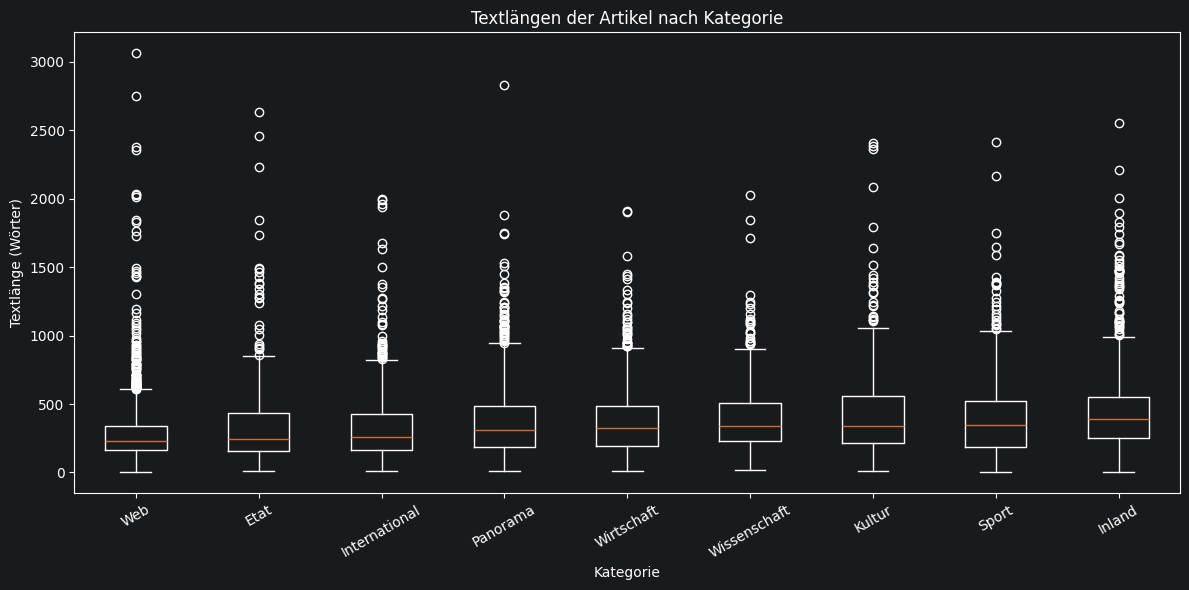

In [11]:
import matplotlib.pyplot as plt

order = stats.sort_values("Median").index
data = [df.loc[df["label"] == cat, "word_count"] for cat in order]

fig, ax = plt.subplots(figsize=(12, 6))
ax.boxplot(data, tick_labels=order, showfliers=True)
ax.set_title("Textlängen der Artikel nach Kategorie")
ax.set_xlabel("Kategorie")
ax.set_ylabel("Textlänge (Wörter)")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()
